### Build a basic ChatBot With Langgraph (Graph API )

Components of langgraph :
1. Edge 
2. Node
3. State

In [29]:
from typing import Annotated
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START ,END
from langgraph.graph.message import add_messages   # Reducer: used for proper convo append.
import os 
from dotenv import load_dotenv
load_dotenv()

True

In [30]:
class State(TypedDict):
    messages:Annotated[list,add_messages]
    
from langchain_groq import ChatGroq
llm=ChatGroq(model="qwen/qwen3.8-27b")
def chatbot(state:State):
    return {"messages":[llm.invoke(state["messages"])]}

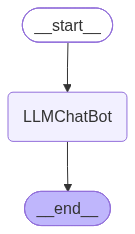

In [31]:
graph_builder=StateGraph(State)

#Adding nodes
graph_builder.add_node("LLMChatBot",chatbot)

#Adding edges
graph_builder.add_edge(START ,"LLMChatBot")
graph_builder.add_edge("LLMChatBot",END)

#Compile the graph
graph=graph_builder.compile()

#Visualization the graph
from IPython.display import Image,display
try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    pass

In [32]:
'''response=graph.invoke({"messages":"hii"})
response["messages"][-1].content'''

for event in graph.stream({"messages":"Hii , How are you ?"}):
    for value in event.values():
        print(value["messages"][-1].content)

Hello! I'm doing well, thank you for asking. How are you? Is there anything specific I can help you with today?


### Chatbot With Tool

### Tavily : 
Tavily is a search engine built specifically for AI agents that automatically scrapes, cleans, and formats real-time web results so LLMs can answer live queries cleanly without wasting tokens on HTML junk.

In [33]:
from langchain_tavily import TavilySearch
tool=TavilySearch(max_result=2)
tool.invoke("What do you mean by langgraph?") 

{'query': 'What do you mean by langgraph?',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'title': 'DO Definition & Meaning | Dictionary.com',
   'url': 'https://www.dictionary.com/browse/do',
   'content': 'To do is to act, perform, or undertake. When you do chores, you engage in the activity of cleaning the kitchen or taking out the trash. Do is one of the most frequently used verbs in English. You do many things in a typical day: you might do the dishes, do your job, and later on, do your taxes. If you meet an old-fashioned gentleman, he might say, "How do you do?" essentially meaning, "Hello." After a difficult test, your friend could ask, "How did you do?" You can also do as you please, or [...] as you please, or just do nothing all day long. [...] 1. to cause the defeat, ruin, or death of.\n   2. Chiefly British. to cook and keep house for; manage or provide for.\n5. do over to redecorate.\n6. do with to gain advantage or benefit from; make use of.\n

In [34]:
### Custom Function
def Multiply(a:int,b:int)->int:
    """Multiply a and b
    args:
       a(int): first int
       b(int): Second int

    returns :
       int : output int
    """
    return a*b
tools=[tool,Multiply]
llm_with_tool=llm.bind_tools(tools)  # Binding tools with LLM
llm_with_tool

_ChatModelBinding(bound=ChatGroq(metadata={'lc_versions': {'langchain-core': '1.7.1', 'langchain': '1.4.7'}}, client=<groq.resources.chat.completions.Completions object at 0x000002474DB042D0>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x000002474DB04CD0>, model_name='qwen/qwen3.8-27b', model_kwargs={}, groq_api_key=SecretStr('**********')), kwargs={'tools': [{'type': 'function', 'function': {'name': 'tavily_search', 'description': 'A search engine optimized for comprehensive, accurate, and trusted results. Useful for when you need to answer questions about current events. It not only retrieves URLs and snippets, but offers advanced search depths, domain management, time range filters, and image search, this tool delivers real-time, accurate, and citation-backed results.Input should be a search query.', 'parameters': {'properties': {'query': {'description': 'Search query to look up', 'type': 'string'}, 'include_domains': {'anyOf': [{'items': {'type': 'stri

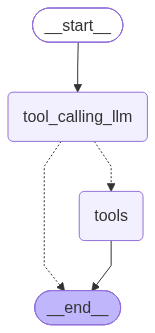

In [35]:
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition
## Node definition
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tool.invoke(state["messages"])]}

## Graph 
builder=StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools) )

## Add Edges
builder.add_edge(START,"tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    #If the latest msg (result) from assistant is a tool call -> tools_condition routes to tools 
    #If the latest msg (result) from assistant is a not a tool call-> tools_condition routes to END
    tools_condition
)
builder.add_edge("tools",END)

## Compile the graph
graph=builder.compile()
display(Image(graph.get_graph().draw_mermaid_png()))

In [36]:
response=graph.invoke({"messages":"What is the recent AI news ?"})
response['messages'][-1].content

"Here are the most recent AI news developments from July 2026:\n\n1. **OpenAI's First Major AI Chip** – OpenAI has unveiled its first major AI chip, designed to be manufactured by Broadcom. The chip is part of a multi-billion dollar deal and is expected to come online in late 2026, initially powering OpenAI's AI data centers in North Texas.\n\n2. **Musk's xAI Launches Grok 4.5** – Elon Musk's xAI has launched Grok 4.5, its newest AI model, which has been well-received by AI developers. However, the launch has sparked new concerns about the company's AI-generated video technology.\n\n3. **AI's Environmental Impact** – A new study has revealed that the environmental costs of AI are growing faster than expected, with electricity emissions from AI data centers quadrupling in just two years.\n\n4. **AI and the Job Market** – A report from World Economic Forum and LinkedIn has raised concerns about AI's impact on the job market, predicting that AI could displace 10 million jobs by 2030, part

In [37]:
response=graph.invoke({"messages":"What is the recent AI news ?"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

What is the recent AI news ?
================================== Ai Message ==================================

I don't have access to real-time information, so I can't provide the very latest AI news. However, I can search for recent AI developments if you'd like! Would you like me to look up the most recent AI news for you?


In [38]:
response=graph.invoke({"messages":"What is the recent AI news and what us 5 multiply by 6 ?"})
for m in response['messages']:
    m.pretty_print()


================================ Human Message =================================

What is the recent AI news and what us 5 multiply by 6 ?
================================== Ai Message ==================================

I'll handle both parts of your question. Let me search for recent AI news and calculate the multiplication.
Tool Calls:
  tavily_search (dgvnjk0hs)
 Call ID: dgvnjk0hs
  Args:
    query: latest AI news
    time_range: week
    topic: news
  Multiply (a6mtp6zws)
 Call ID: a6mtp6zws
  Args:
    a: 5
    b: 6
================================= Tool Message =================================
Name: tavily_search

{"query": "latest AI news", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.euronews.com/2026/10/29/mistral-releases-latest-ai-model-for-download-giving-companies-more-control-over-their-cyb", "title": "Mistral releases latest AI model for download, giving companies more control over their cybersecurity | Euronews", "conten

### ReAct Agent Architecture
- Act 
- Observe
- Reason

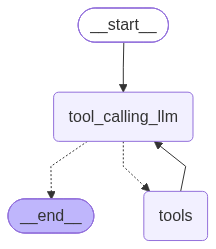

In [39]:
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition
## Node definition
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tool.invoke(state["messages"])]}

## Graph 
builder=StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools) )

## Add Edges
builder.add_edge(START,"tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    #If the latest msg (result) from assistant is a tool call -> tools_condition routes to tools 
    #If the latest msg (result) from assistant is a not a tool call-> tools_condition routes to END
    tools_condition
)
builder.add_edge("tools","tool_calling_llm")

## Compile the graph
graph=builder.compile()
display(Image(graph.get_graph().draw_mermaid_png()))

In [40]:
response=graph.invoke({"messages":"Give me the latest AI news and then multiply 5 by 10 "})
for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

Give me the latest AI news and then multiply 5 by 10 
================================== Ai Message ==================================

I'll fetch the latest AI news and perform the multiplication for you.
Tool Calls:
  tavily_search (296pb4dar)
 Call ID: 296pb4dar
  Args:
    end_date: None
    exclude_domains: []
    include_domains: []
    include_images: False
    query: latest AI news
    search_depth: None
    start_date: None
    time_range: None
    topic: None
  Multiply (er0btjhc1)
 Call ID: er0btjhc1
  Args:
    a: 5
    b: 10
================================= Tool Message =================================
Name: tavily_search

{"query": "latest AI news", "follow_up_questions": null, "answer": null, "images": [], "results": [{"title": "The latest AI news we announced in September 2026", "url": "https://blog.google/innovation-and-ai/technology/ai/google-ai-updates-september-2026", "content": "Che

### Adding Memory in Agentic Graph

An example why memory neccessary 

In [41]:
response=graph.invoke({"messages":"My name is divya "})
for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

My name is divya 
================================== Ai Message ==================================

Hello Divya! It's nice to meet you. How can I help you today?


In [42]:
response=graph.invoke({"messages":"What is my name?"})
for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

What is my name?
================================== Ai Message ==================================

I don't know your name, as you haven't told me yet! How would you like to be addressed?


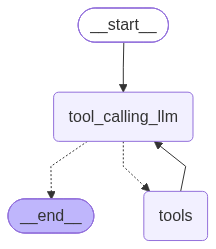

In [43]:
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition
from langgraph.checkpoint.memory import MemorySaver
## Node definition
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tool.invoke(state["messages"])]}

memory=MemorySaver()

## Graph 
builder=StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools) )

## Add Edges
builder.add_edge(START,"tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    #If the latest msg (result) from assistant is a tool call -> tools_condition routes to tools 
    #If the latest msg (result) from assistant is a not a tool call-> tools_condition routes to END
    tools_condition
)
builder.add_edge("tools","tool_calling_llm")

## Compile the graph
graph=builder.compile(checkpointer=memory)
display(Image(graph.get_graph().draw_mermaid_png()))

In [44]:
config={"configurable":{"thread_id":"test_2"}}
response=graph.invoke({"messages":"Hii ,My name is Divya ."},config=config)
for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

Hii ,My name is Divya .
================================== Ai Message ==================================

Hi Divya! It's nice to meet you. How can I help you today?


In [45]:
response=graph.invoke({"messages":"Hii ,What is my name?"},config=config)
for m in response["messages"]:
    m.pretty_print()

================================ Human Message =================================

Hii ,My name is Divya .
================================== Ai Message ==================================

Hi Divya! It's nice to meet you. How can I help you today?
================================ Human Message =================================

Hii ,What is my name?
================================== Ai Message ==================================

Your name is Divya.


In [69]:
from langgraph.checkpoint.memory import MemorySaver
memory=MemorySaver()

def superbot(state:State):
    return {"messages":[llm.invoke(state['messages'])]}



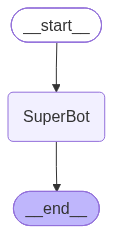

{'messages': [HumanMessage(content='Hii,My name is divya and i like coding.', additional_kwargs={}, response_metadata={}, id='9a2ca350-ac37-40cf-a9ac-6802d8cf10a9'),
  AIMessage(content='Hi Divya! 👋 It’s great to meet you.\n\nCoding is a fantastic skill and a very rewarding hobby. Whether you’re just starting out, working on specific projects, or looking for new languages to learn, I’d be happy to help.\n\nWhat are you currently working on or learning? (e.g., Python, JavaScript, web development, algorithms, etc.)', additional_kwargs={}, response_metadata={'token_usage': {'completion_tokens': 78, 'prompt_tokens': 25, 'total_tokens': 103, 'completion_time': 0.148601104, 'completion_tokens_details': None, 'prompt_time': 0.001435598, 'prompt_tokens_details': None, 'queue_time': 0.051093652, 'total_time': 0.150036702}, 'model_name': 'qwen/qwen3.8-27b', 'system_fingerprint': 'fp_a1293f40b5', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id

In [70]:
graph=StateGraph(State)
## Node
graph.add_node("SuperBot",superbot)

##Edges
graph.add_edge(START,"SuperBot")
graph.add_edge("SuperBot",END)

graph_builder=graph.compile(checkpointer=memory)

#Display
from IPython.display import Image,display
display(Image(graph_builder.get_graph().draw_mermaid_png()))

## Invocation
config={"configurable":{"thread_id":"1"}}
graph_builder.invoke({"messages":"Hii,My name is divya and i like coding."},config=config)


### Streaming 
Methods : .stream() and astream()
- These methods are sync and async methods for streaming back result.
Additional parameters in streaming modes for ggraph state
- Value: This streams the full state of the graph after each node is called.
- Updates : This streams updates to the state of the graph after eachc node is called. 

In [71]:
#Create a thread
config={"configurable":{"thread_id":"1"}}
for chunk in graph_builder.stream({"messages":"Hii,my name is divya and i like coding."},config,stream_mode="updates"):
    print(chunk)

{'SuperBot': {'messages': [AIMessage(content='Hi Divya! 👋 It’s great to meet you.\n\nCoding is a fantastic skill and a very rewarding hobby. Whether you’re just starting out, working on specific projects, or looking for new languages to learn, I’d be happy to help.\n\nWhat are you currently working on or learning? (e.g., Python, JavaScript, web development, algorithms, etc.)', additional_kwargs={}, response_metadata={'token_usage': {'completion_tokens': 78, 'prompt_tokens': 129, 'total_tokens': 207, 'completion_time': 0.148921109, 'completion_tokens_details': None, 'prompt_time': 0.009159808, 'prompt_tokens_details': None, 'queue_time': 0.049013522, 'total_time': 0.158080917}, 'model_name': 'qwen/qwen3.8-27b', 'system_fingerprint': 'fp_a1293f40b5', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a192bc-bd9c-7353-aa14-b7a24434fb5e-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 129, 'output_tokens

In [73]:
config={"configurable":{"thread_id":"2"}}
async for chunk in graph_builder.astream_events({"messages":"Hii,my name is divya and i like coding."},config,version="v2"):
    print(chunk)

{'event': 'on_chain_start', 'data': {'input': {'messages': 'Hii,my name is divya and i like coding.'}}, 'name': 'LangGraph', 'tags': [], 'run_id': '01a192be-66d1-7558-81eb-efbd70540435', 'metadata': {'thread_id': '2', 'ls_integration': 'langgraph'}, 'parent_ids': []}
{'event': 'on_chain_start', 'data': {'input': {'messages': [HumanMessage(content='Hii,my name is divya and i like coding.', additional_kwargs={}, response_metadata={}, id='961ae86a-5bb3-44dc-aeef-4ac1b80f555b')]}}, 'name': 'SuperBot', 'tags': ['graph:step:1'], 'run_id': '01a192be-66d5-73c9-8cf2-4be7dae45780', 'metadata': {'thread_id': '2', 'ls_integration': 'langgraph', 'langgraph_step': 1, 'langgraph_node': 'SuperBot', 'langgraph_triggers': ('branch:to:SuperBot',), 'langgraph_path': ('__pregel_pull', 'SuperBot'), 'langgraph_checkpoint_ns': 'SuperBot:4220a71f-a006-f92b-1ac7-6a1c1195bc8c'}, 'parent_ids': ['01a192be-66d1-7558-81eb-efbd70540435']}
{'event': 'on_chat_model_start', 'data': {'input': {'messages': [[HumanMessage(